In [2]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스


In [3]:
df = pd.read_csv('data/LinearRegressionData.csv')
df.head()

data = df.iloc[:, :-1].values # 처음부터 마지막 컬럼 직전까지의 데이터 (독립 변수 - 원인)
label = df.iloc[:, -1].values # 마지막 컬럼 데이터 (종속 변수 - 결과)
# 훈련데이터, 테스트데이터 분류
train_data, test_data, train_label, test_label = train_test_split(
data, label, random_state=42)  # 회귀 : stratify 사용하지 않음

In [6]:
# 다항회귀 구현
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))

# 선형 회귀모델 적용시 
lr = LinearRegression()

lr.fit(train_poly, train_label)
hour1 = 3.5   
hour2 = 8.9

# 시간 3.5, 8.9 예측
predict = lr.predict([[hour1**2,hour1]])
predict2 = lr.predict([[hour2**2,hour2]])

In [7]:
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)

train정확도 :  0.9851938548998579
test정확도 :  0.8121250587972448


[-0.58329547 17.42329379] -16.331738919599772


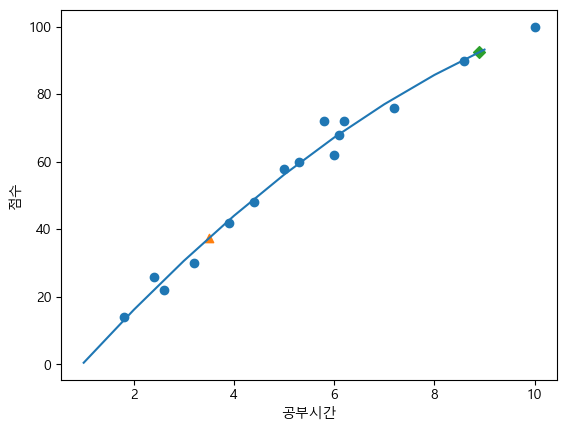

In [ ]:
point = np.arange(1,10)
print(lr.coef_, lr.intercept_)

# 산점도 그래프
plt.scatter(train_data, train_label)
# 3.5
plt.scatter(hour1, predict, marker='^')
# 8.9
plt.scatter(hour2, predict2, marker='D')
# 2차원 그래프 
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('공부시간')
plt.ylabel('점수')
plt.show()



In [5]:
# LinearRegression 모델 적용
lr = LinearRegression()
lr.fit(train_poly,train_label)
print('정확도 : ',lr.score(train_poly,train_label))
print('정확도 : ',lr.score(test_poly,test_label))


정확도 :  0.9851938548998579
정확도 :  0.8121250587972448
